<a href="https://colab.research.google.com/github/nyirongo17/Toll_Plaza_Traffic_Pridiction/blob/main/NRFA_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
data = {
    "Traffic_Volume": [
        80, 100, 120, 150, 180, 200, 230, 260, 300, 340,
        110, 140, 170, 210, 250, 290, 330, 370, 400, 450,
        90, 130, 160, 190, 220, 270, 310, 350, 420, 480
    ],

    "Queue_Length": [
        3, 4, 5, 6, 8, 10, 12, 15, 18, 22,
        4, 5, 7, 9, 13, 16, 20, 24, 28, 32,
        3, 5, 6, 8, 11, 14, 17, 21, 30, 35
    ],

    "Transaction_Time": [
        18, 20, 22, 24, 25, 28, 30, 32, 35, 38,
        19, 21, 23, 27, 29, 33, 36, 40, 43, 48,
        18, 20, 22, 26, 28, 31, 34, 39, 45, 50
    ],

    "Active_Lanes": [
        5, 5, 5, 5, 5, 5, 4, 4, 4, 3,
        5, 5, 5, 4, 4, 4, 3, 3, 3, 2,
        5, 5, 5, 5, 4, 4, 4, 3, 3, 2
    ],

    "Congestion": [
        0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 0, 1, 1, 1, 1, 1
    ]
}

df = pd.DataFrame(data)

df

,Traffic_Volume,Queue_Length,Transaction_Time,Active_Lanes,Congestion
0,80,3,18,5,0
1,100,4,20,5,0
2,120,5,22,5,0
3,150,6,24,5,0
4,180,8,25,5,0
5,200,10,28,5,0
6,230,12,30,4,0
7,260,15,32,4,1
8,300,18,35,4,1
9,340,22,38,3,1


The 5 features: Trafic volime, Queue_length , Transaction_Time, Active_lens, Congestion


In [ ]:
print("Number of records:", len(df))

print("\nFirst five records:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

Number of records: 30

First five records:
   Traffic_Volume  Queue_Length  Transaction_Time  Active_Lanes  Congestion
0              80             3                18             5           0
1             100             4                20             5           0
2             120             5                22             5           0
3             150             6                24             5           0
4             180             8                25             5           0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Traffic_Volume    30 non-null     int64
 1   Queue_Length      30 non-null     int64
 2   Transaction_Time  30 non-null     int64
 3   Active_Lanes      30 non-null     int64
 4   Congestion        30 non-null     int64
dtypes: int64(5)
memory usage: 1.3 KB
None

Missing values:
Tr

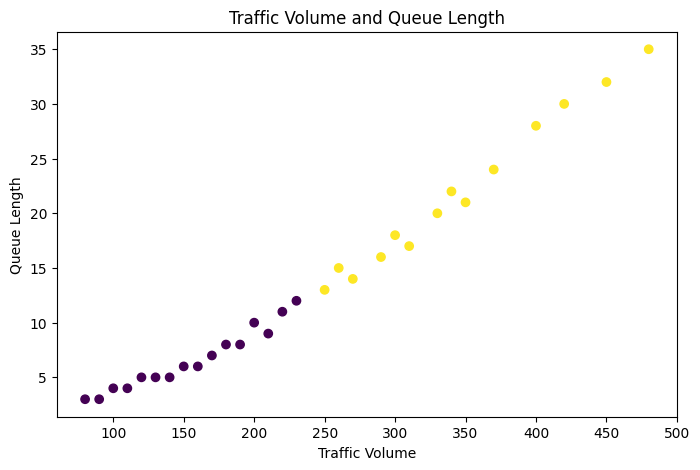

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Traffic_Volume"],
    df["Queue_Length"],
    c=df["Congestion"]
)

plt.xlabel("Traffic Volume")
plt.ylabel("Queue Length")
plt.title("Traffic Volume and Queue Length")

plt.show()

In [ ]:
X = df[
    [
        "Traffic_Volume",
        "Queue_Length",
        "Transaction_Time",
        "Active_Lanes"
    ]
]

y = df["Congestion"]

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
   Traffic_Volume  Queue_Length  Transaction_Time  Active_Lanes
0              80             3                18             5
1             100             4                20             5
2             120             5                22             5
3             150             6                24             5
4             180             8                25             5

Target:
0    0
1    0
2    0
3    0
4    0
Name: Congestion, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 21
Testing records: 9


In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [ ]:
predictions = model.predict(X_test)

results = X_test.copy()

results["Actual_Congestion"] = y_test.values
results["Predicted_Congestion"] = predictions

results

,Traffic_Volume,Queue_Length,Transaction_Time,Active_Lanes,Actual_Congestion,Predicted_Congestion
10,110,4,19,5,0,0
16,330,20,36,3,1,1
21,130,5,20,5,0,0
18,400,28,43,3,1,1
3,150,6,24,5,0,0
8,300,18,35,4,1,1
6,230,12,30,4,0,0
13,210,9,27,4,0,0
15,290,16,33,4,1,1


In [ ]:
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Model Accuracy: 100.0 %

Confusion Matrix:
[[5 0]
 [0 4]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         4

    accuracy                           1.00         9
   macro avg       1.00      1.00      1.00         9
weighted avg       1.00      1.00      1.00         9



In [ ]:
new_data = pd.DataFrame({
    "Traffic_Volume": [360],
    "Queue_Length": [23],
    "Transaction_Time": [40],
    "Active_Lanes": [3]
})

prediction = model.predict(new_data)

if prediction[0] == 1:
    print("WARNING: Congestion is predicted.")
else:
    print("Traffic is expected to flow normally.")

In [ ]:
probability = model.predict_proba(new_data)

congestion_probability = probability[0][1] * 100

print(
    "Probability of congestion:",
    round(congestion_probability, 2),
    "%"
)

Probability of congestion: 100.0 %


In [ ]:
if congestion_probability >= 70:

    print("HIGH RISK OF CONGESTION")
    print("Recommended actions:")
    print("- Open additional toll lanes")
    print("- Encourage electronic or cashless payment")
    print("- Deploy additional toll staff")
    print("- Monitor the queue continuously")

elif congestion_probability >= 40:

    print("MODERATE RISK OF CONGESTION")
    print("Recommended action:")
    print("- Prepare additional lanes and staff")

else:

    print("LOW RISK OF CONGESTION")
    print("Continue normal operations")

HIGH RISK OF CONGESTION
Recommended actions:
- Open additional toll lanes
- Encourage electronic or cashless payment
- Deploy additional toll staff
- Monitor the queue continuously
